# Laboratorio 8: Monte Carlo y Cadenas de Markov (MCMC)


In [1]:
# Librerías generales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import math

# Integración numérica y distribuciones
from scipy import integrate
from scipy.stats import norm

# Para que los resultados sean reproducibles
np.random.seed(123)
random.seed(123)

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

# Constantes físicas en unidades del SI
K_B = 1.380649e-23       # J/K
MU_B = 9.2740100783e-24  # J/T

# Relación mu_B / k_B. Permite escribir el campo magnético en Tesla
# y la temperatura en Kelvin dentro de la simulación.
MU_B_OVER_K_B = MU_B / K_B

print(f'mu_B / k_B = {MU_B_OVER_K_B:.10f} K/T')


mu_B / k_B = 0.6717138156 K/T


In [2]:
# ************************************************************
# Rutina de integración Monte Carlo vista en clase
# ************************************************************
def monte_carlo_integration(func, a, b, num_samples=1000):
    """
    Aproxima la integral definida de func en [a, b] usando Monte Carlo.

    Parámetros
    ----------
    func : callable
        Función a integrar.
    a, b : float
        Límites de integración.
    num_samples : int
        Número de puntos aleatorios.

    Retorna
    -------
    float
        Aproximación de la integral.
    """
    integral_sum = 0.0
    for _ in range(num_samples):
        # Punto aleatorio uniforme en [a, b]
        x = random.uniform(a, b)
        integral_sum += func(x)

    # Promedio de f multiplicado por el ancho del intervalo
    return (b - a) * integral_sum / num_samples


# ************************************************************
# Versión vectorizada de la misma idea
# ************************************************************
def mc_integral_vectorizada(func, a, b, num_samples=1000, rng=None):
    """
    Versión vectorizada de la integración Monte Carlo.

    Además de la estimación, devuelve el error estándar de la media:
        error = (b - a) * std(f(x_i)) / sqrt(N).
    """
    if rng is None:
        rng = np.random.default_rng()

    x = rng.uniform(a, b, num_samples)
    valores = func(x)
    estimacion = (b - a) * np.mean(valores)
    error_estandar = (b - a) * np.std(valores, ddof=1) / np.sqrt(num_samples)

    return estimacion, error_estandar


Valor analítico:             5.3333333333
Valor con scipy.quad:        5.3333333333
Error estimado por quad:     5.92e-15


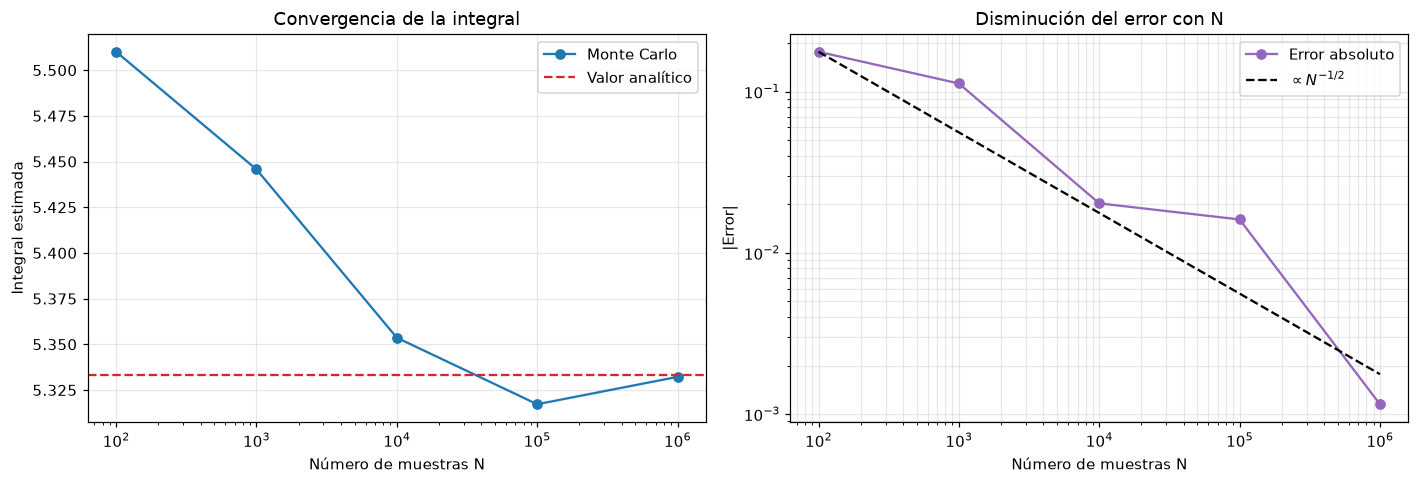

,N,Estimación MC,Error absoluto,Error relativo (%),Error estándar
0,100,5.510047,0.176714,3.313381,0.169350
1,1000,5.445691,0.112357,2.106702,0.059283
2,10000,5.353610,0.020277,0.380190,0.018691
3,100000,5.317223,0.016110,0.302060,0.005982
4,1000000,5.332183,0.001150,0.021570,0.001886


In [3]:
# Función a integrar y límites
f_sqrt = lambda x: np.sqrt(x)
a, b = 0.0, 4.0

# Resultado analítico
exacto_1 = 16.0 / 3.0

# Resultado con integración numérica de SciPy
quad_1, error_quad_1 = integrate.quad(f_sqrt, a, b)

print(f'Valor analítico:             {exacto_1:.10f}')
print(f'Valor con scipy.quad:        {quad_1:.10f}')
print(f'Error estimado por quad:     {error_quad_1:.2e}')

# Diferentes números de muestras
N_valores = [10**2, 10**3, 10**4, 10**5, 10**6]
rng = np.random.default_rng(2026)

filas = []
for N in N_valores:
    estimacion, error_est = mc_integral_vectorizada(f_sqrt, a, b, N, rng)
    filas.append({
        'N': N,
        'Estimación MC': estimacion,
        'Error absoluto': abs(estimacion - exacto_1),
        'Error relativo (%)': 100 * abs(estimacion - exacto_1) / exacto_1,
        'Error estándar': error_est,
    })

tabla_1 = pd.DataFrame(filas)

# Gráficas de convergencia
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(tabla_1['N'], tabla_1['Estimación MC'], 'o-', color='tab:blue', label='Monte Carlo')
axes[0].axhline(exacto_1, color='tab:red', linestyle='--', label='Valor analítico')
axes[0].set_xscale('log')
axes[0].set_xlabel('Número de muestras N')
axes[0].set_ylabel('Integral estimada')
axes[0].set_title('Convergencia de la integral')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].loglog(tabla_1['N'], tabla_1['Error absoluto'], 'o-', color='tab:purple', label='Error absoluto')
# Línea de referencia con pendiente -1/2
referencia = tabla_1['Error absoluto'].iloc[0] * np.sqrt(tabla_1['N'].iloc[0] / tabla_1['N'])
axes[1].loglog(tabla_1['N'], referencia, 'k--', label=r'$\propto N^{-1/2}$')
axes[1].set_xlabel('Número de muestras N')
axes[1].set_ylabel('|Error|')
axes[1].set_title('Disminución del error con N')
axes[1].grid(alpha=0.3, which='both')
axes[1].legend()

plt.tight_layout()
plt.show()

tabla_1


Media de las estimaciones:       5.333722
Desviación estándar observada:   0.018814
Error estándar teórico:          0.018856
Valor exacto:                    5.333333


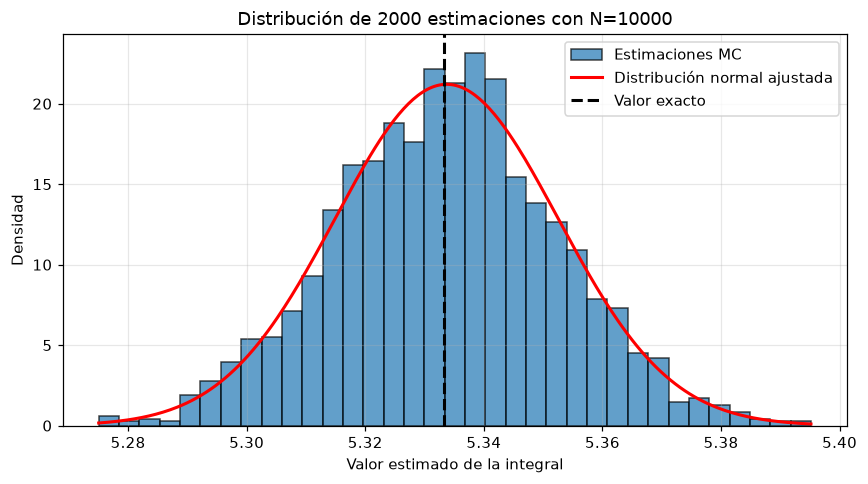

In [4]:
# Muchas realizaciones independientes de la misma integral
N_hist = 10_000
repeticiones = 2_000
rng_hist = np.random.default_rng(7)

estimaciones_1 = np.array([
    mc_integral_vectorizada(f_sqrt, a, b, N_hist, rng_hist)[0]
    for _ in range(repeticiones)
])

media_1 = estimaciones_1.mean()
std_1 = estimaciones_1.std(ddof=1)

# Error estándar teórico para N_hist muestras
# Var[f(X)] con X ~ U(0,4): E[f^2] - E[f]^2 = 2 - (4/3)^2 = 2/9
error_teorico_1 = (b - a) * np.sqrt(2 / 9) / np.sqrt(N_hist)

print(f'Media de las estimaciones:       {media_1:.6f}')
print(f'Desviación estándar observada:   {std_1:.6f}')
print(f'Error estándar teórico:          {error_teorico_1:.6f}')
print(f'Valor exacto:                    {exacto_1:.6f}')

plt.figure(figsize=(8, 4.5))
plt.hist(estimaciones_1, bins=35, density=True, alpha=0.7,
         color='tab:blue', edgecolor='black', label='Estimaciones MC')
x_hist = np.linspace(estimaciones_1.min(), estimaciones_1.max(), 300)
plt.plot(x_hist, norm.pdf(x_hist, media_1, std_1), 'r-', lw=2, label='Distribución normal ajustada')
plt.axvline(exacto_1, color='k', linestyle='--', lw=2, label='Valor exacto')
plt.xlabel('Valor estimado de la integral')
plt.ylabel('Densidad')
plt.title(f'Distribución de {repeticiones} estimaciones con N={N_hist}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Valor analítico:             0.6666666667
Valor con scipy.dblquad:     0.6666666667
Error estimado por dblquad:  7.40e-15


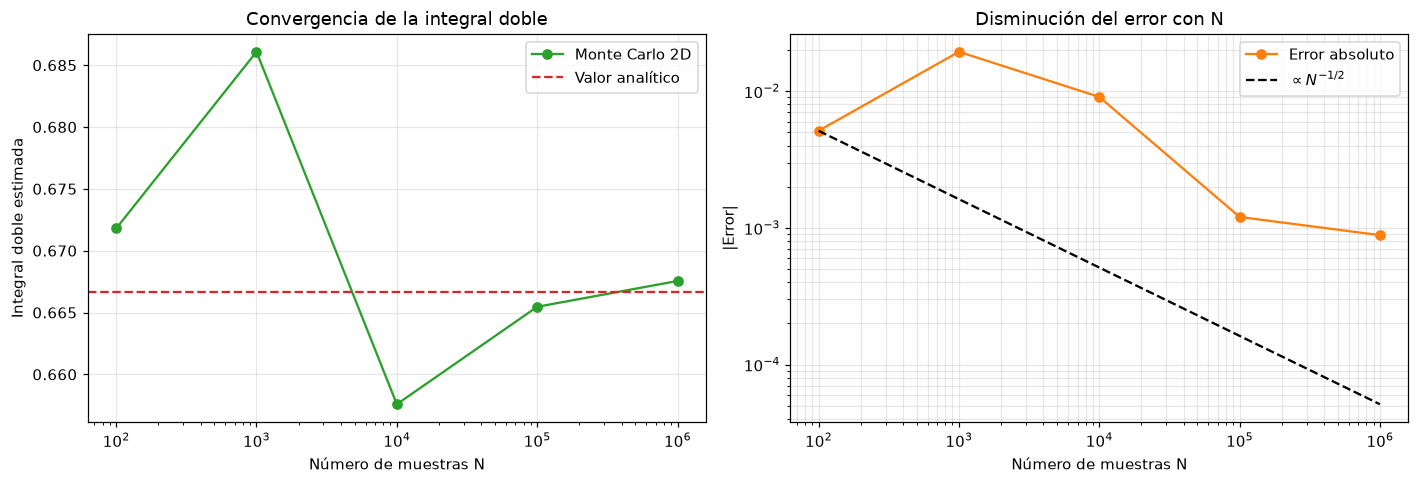

,N,Estimación MC,Error absoluto,Error relativo (%),Error estándar
0,100,0.671797,0.005130,0.769497,0.085856
1,1000,0.686082,0.019416,2.912360,0.024565
2,10000,0.657585,0.009081,1.362175,0.007779
3,100000,0.665465,0.001202,0.180297,0.002486
4,1000000,0.667551,0.000885,0.132705,0.000790


In [5]:
# Función y región de integración
f_xy = lambda x, y: x * y**2
xmin, xmax = 0.0, 2.0
ymin, ymax = 0.0, 1.0

# Resultado analítico y resultado de SciPy
exacto_2 = 2.0 / 3.0
quad_2, error_quad_2 = integrate.dblquad(
    lambda y, x: x * y**2,
    xmin, xmax,
    lambda x: ymin, lambda x: ymax,
)

print(f'Valor analítico:             {exacto_2:.10f}')
print(f'Valor con scipy.dblquad:     {quad_2:.10f}')
print(f'Error estimado por dblquad:  {error_quad_2:.2e}')


def mc_integral_2d(func, xmin, xmax, ymin, ymax, num_samples=1000, rng=None):
    """
    Integración Monte Carlo de una función de dos variables sobre un rectángulo.

    Retorna la estimación y el error estándar.
    """
    if rng is None:
        rng = np.random.default_rng()

    x = rng.uniform(xmin, xmax, num_samples)
    y = rng.uniform(ymin, ymax, num_samples)
    area = (xmax - xmin) * (ymax - ymin)
    valores = func(x, y)

    estimacion = area * np.mean(valores)
    error_estandar = area * np.std(valores, ddof=1) / np.sqrt(num_samples)
    return estimacion, error_estandar


rng_2d = np.random.default_rng(2027)
filas_2d = []
for N in N_valores:
    estimacion, error_est = mc_integral_2d(f_xy, xmin, xmax, ymin, ymax, N, rng_2d)
    filas_2d.append({
        'N': N,
        'Estimación MC': estimacion,
        'Error absoluto': abs(estimacion - exacto_2),
        'Error relativo (%)': 100 * abs(estimacion - exacto_2) / exacto_2,
        'Error estándar': error_est,
    })

tabla_2 = pd.DataFrame(filas_2d)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(tabla_2['N'], tabla_2['Estimación MC'], 'o-', color='tab:green', label='Monte Carlo 2D')
axes[0].axhline(exacto_2, color='tab:red', linestyle='--', label='Valor analítico')
axes[0].set_xscale('log')
axes[0].set_xlabel('Número de muestras N')
axes[0].set_ylabel('Integral doble estimada')
axes[0].set_title('Convergencia de la integral doble')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].loglog(tabla_2['N'], tabla_2['Error absoluto'], 'o-', color='tab:orange', label='Error absoluto')
referencia_2 = tabla_2['Error absoluto'].iloc[0] * np.sqrt(tabla_2['N'].iloc[0] / tabla_2['N'])
axes[1].loglog(tabla_2['N'], referencia_2, 'k--', label=r'$\propto N^{-1/2}$')
axes[1].set_xlabel('Número de muestras N')
axes[1].set_ylabel('|Error|')
axes[1].set_title('Disminución del error con N')
axes[1].grid(alpha=0.3, which='both')
axes[1].legend()

plt.tight_layout()
plt.show()

tabla_2


Media de las estimaciones:       0.666497
Desviación estándar observada:   0.007835
Valor exacto:                    0.666667


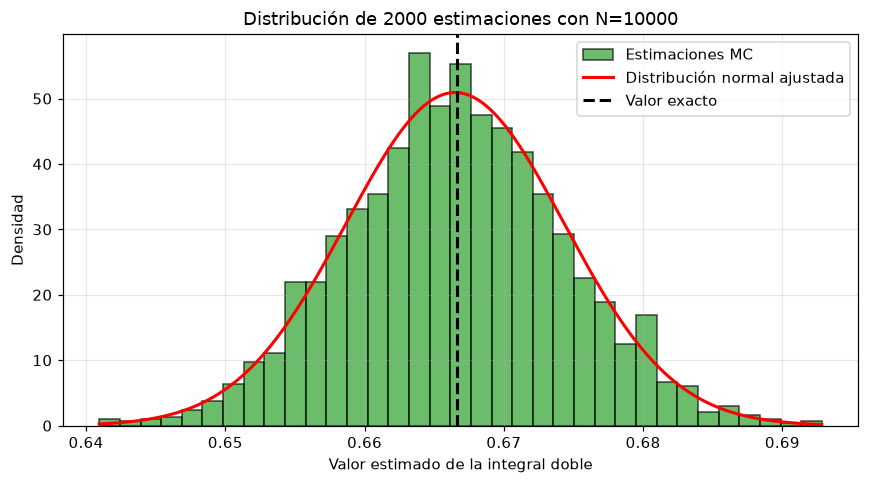

In [6]:
# Histograma de estimaciones de la integral doble
N_hist_2 = 10_000
repeticiones_2 = 2_000
rng_hist_2 = np.random.default_rng(11)

estimaciones_2 = np.array([
    mc_integral_2d(f_xy, xmin, xmax, ymin, ymax, N_hist_2, rng_hist_2)[0]
    for _ in range(repeticiones_2)
])

media_2 = estimaciones_2.mean()
std_2 = estimaciones_2.std(ddof=1)

print(f'Media de las estimaciones:       {media_2:.6f}')
print(f'Desviación estándar observada:   {std_2:.6f}')
print(f'Valor exacto:                    {exacto_2:.6f}')

plt.figure(figsize=(8, 4.5))
plt.hist(estimaciones_2, bins=35, density=True, alpha=0.7,
         color='tab:green', edgecolor='black', label='Estimaciones MC')
x_hist_2 = np.linspace(estimaciones_2.min(), estimaciones_2.max(), 300)
plt.plot(x_hist_2, norm.pdf(x_hist_2, media_2, std_2), 'r-', lw=2, label='Distribución normal ajustada')
plt.axvline(exacto_2, color='k', linestyle='--', lw=2, label='Valor exacto')
plt.xlabel('Valor estimado de la integral doble')
plt.ylabel('Densidad')
plt.title(f'Distribución de {repeticiones_2} estimaciones con N={N_hist_2}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Ejercicio 2. Modelo de Ising 2D



In [8]:
def energia_total(red, J=0.0, h=0.0):
    """
    Energía total del modelo de Ising 2D con condiciones periódicas.

        E = -J * sum_<ij> s_i s_j - h * sum_i s_i

    La suma de primeros vecinos se calcula con np.roll. Como cada enlace
    aparece dos veces, se multiplica por 1/2.
    """
    suma_horizontal = np.sum(red * np.roll(red, 1, axis=0))
    suma_vertical = np.sum(red * np.roll(red, 1, axis=1))
    return -0.5 * J * (suma_horizontal + suma_vertical) - h * np.sum(red)


def metropolis_ising(L=32, T=5.0, H=0.0, J=0.0, mu=MU_B_OVER_K_B,
                     n_equil=300, n_med=1000, seed=None, inicial=None):
    """
    Simulación de Ising 2D con el algoritmo de Metrópolis.

    Parámetros
    ----------
    L : int
        Tamaño de la red (L x L).
    T : float
        Temperatura en Kelvin (o en unidades de J/k_B si se usan unidades reducidas).
    H : float
        Campo magnético externo en Tesla (o campo reducido).
    J : float
        Constante de acoplamiento entre primeros vecinos. Debe estar en las
        mismas unidades de energía que T (Kelvin si T está en Kelvin).
    mu : float
        Relación mu_B/k_B en K/T. Para unidades reducidas se puede tomar mu=1.
    n_equil : int
        Número de barridos de equilibración que se descartan.
    n_med : int
        Número de barridos sobre los que se promedia.
    seed : int or None
        Semilla del generador aleatorio.
    inicial : ndarray or None
        Configuración inicial de espines. Si es None se genera una
        configuración aleatoria. Para temperaturas bajas conviene iniciar
        desde una configuración ordenada para evitar dominios metaestables.

    Retorna
    -------
    red : ndarray
        Configuración final de espines.
    magnetizaciones : ndarray
        Magnetización por espín en cada barrido de medición.
    energias : ndarray
        Energía total en cada barrido de medición.
    tasa_aceptacion : float
        Fracción de propuestas aceptadas.
    """
    rng = np.random.default_rng(seed)

    # Configuración inicial: aleatoria o la que se indique
    if inicial is None:
        red = rng.choice([-1, 1], size=(L, L))
    else:
        red = np.array(inicial, dtype=int, copy=True)

    # Campo en unidades de energía (Kelvin si T está en Kelvin)
    h = mu * H

    # Máscara de colores para la actualización tipo tablero de ajedrez
    mascara = (np.indices((L, L)).sum(axis=0) % 2)

    magnetizaciones = np.empty(n_med)
    energias = np.empty(n_med)
    aceptados = 0

    for paso in range(n_equil + n_med):
        for color in (0, 1):
            # Suma de los cuatro primeros vecinos de cada sitio
            vecinos = (np.roll(red, 1, axis=0) + np.roll(red, -1, axis=0)
                       + np.roll(red, 1, axis=1) + np.roll(red, -1, axis=1))

            # Cambio de energía al invertir cada espín
            delta_e = 2 * red * (J * vecinos + h)

            # Probabilidad de aceptación. Si delta_e <= 0, la probabilidad es 1.
            probabilidad = np.exp(np.minimum(0.0, -delta_e / T))

            # Aceptar o rechazar cada propuesta
            aceptar = rng.random((L, L)) < probabilidad
            cambio = (mascara == color) & aceptar
            aceptados += np.count_nonzero(cambio)
            red[cambio] *= -1

        # Guardar observables después de completar un barrido
        if paso >= n_equil:
            magnetizaciones[paso - n_equil] = red.mean()
            energias[paso - n_equil] = energia_total(red, J=J, h=h)

    tasa_aceptacion = aceptados / (2 * L * L * (n_equil + n_med))
    return red, magnetizaciones, energias, tasa_aceptacion


Magnetización media simulada: 0.323596
Magnetización analítica:      0.323774
Tasa de aceptación:           0.338


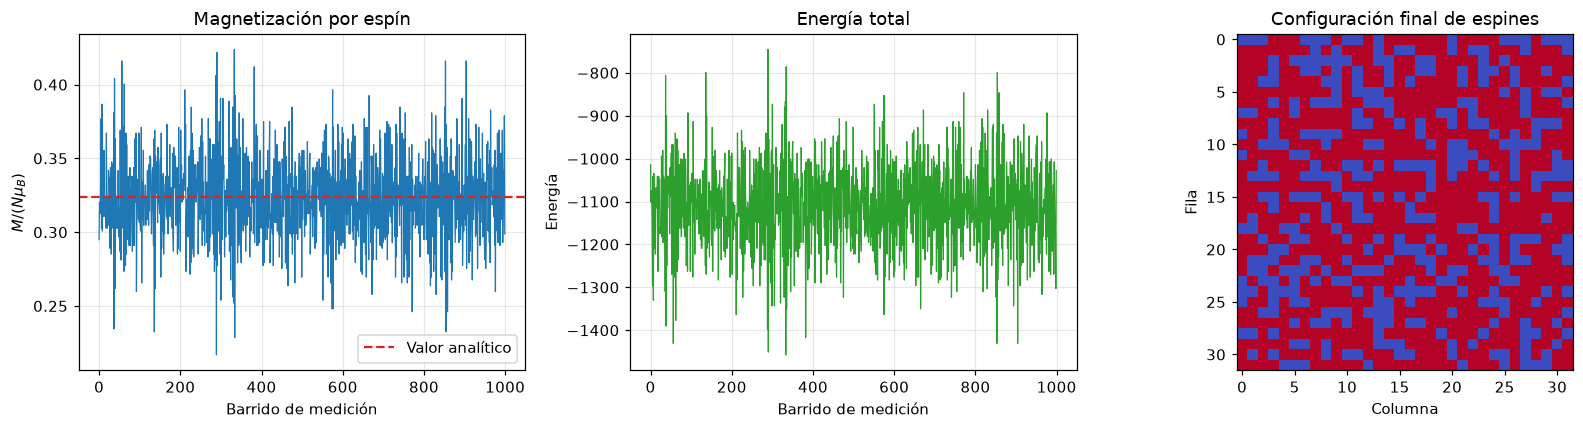

In [9]:
# Prueba de validación: T = 10 K, H = 5 T, J = 0
red_prueba, mags_prueba, energias_prueba, tasa_prueba = metropolis_ising(
    L=32, T=10.0, H=5.0, J=0.0, mu=MU_B_OVER_K_B,
    n_equil=300, n_med=1000, seed=42
)

M_teo_prueba = np.tanh(MU_B_OVER_K_B * 5.0 / 10.0)
print(f'Magnetización media simulada: {mags_prueba.mean():.6f}')
print(f'Magnetización analítica:      {M_teo_prueba:.6f}')
print(f'Tasa de aceptación:           {tasa_prueba:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(mags_prueba, color='tab:blue', lw=0.8)
axes[0].axhline(M_teo_prueba, color='tab:red', linestyle='--', label='Valor analítico')
axes[0].set_title('Magnetización por espín')
axes[0].set_xlabel('Barrido de medición')
axes[0].set_ylabel(r'$M/(N\mu_B)$')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(energias_prueba, color='tab:green', lw=0.8)
axes[1].set_title('Energía total')
axes[1].set_xlabel('Barrido de medición')
axes[1].set_ylabel('Energía')
axes[1].grid(alpha=0.3)

axes[2].imshow(red_prueba, cmap='coolwarm', vmin=-1, vmax=1)
axes[2].set_title('Configuración final de espines')
axes[2].set_xlabel('Columna')
axes[2].set_ylabel('Fila')

plt.tight_layout()
plt.show()


In [10]:
# Temperaturas y campos magnéticos
temperaturas = [5.0, 10.0, 15.0]
campos = np.arange(-30.0, 30.0 + 0.5, 1.0)

rng_simulacion = np.random.default_rng(2026)
registros = []

for T in temperaturas:
    for H in campos:
        semilla = int(rng_simulacion.integers(0, 2**32 - 1))
        red, mags, energias, tasa = metropolis_ising(
            L=32, T=T, H=H, J=0.0, mu=MU_B_OVER_K_B,
            n_equil=300, n_med=1000, seed=semilla
        )
        registros.append({
            'T (K)': T,
            'H (T)': H,
            'M/(N mu_B)': mags.mean(),
            'Error estadístico': mags.std(ddof=1) / np.sqrt(len(mags)),
            'Tasa de aceptación': tasa,
        })

df_ising = pd.DataFrame(registros)
df_ising.head()


,T (K),H (T),M/(N mu_B),Error estadístico,Tasa de aceptación
0,5.0,-30.0,-0.999387,0.000035,0.000488
1,5.0,-29.0,-0.999217,0.000040,0.000577
2,5.0,-28.0,-0.998922,0.000049,0.000727
3,5.0,-27.0,-0.998672,0.000050,0.000862
4,5.0,-26.0,-0.998145,0.000061,0.001119


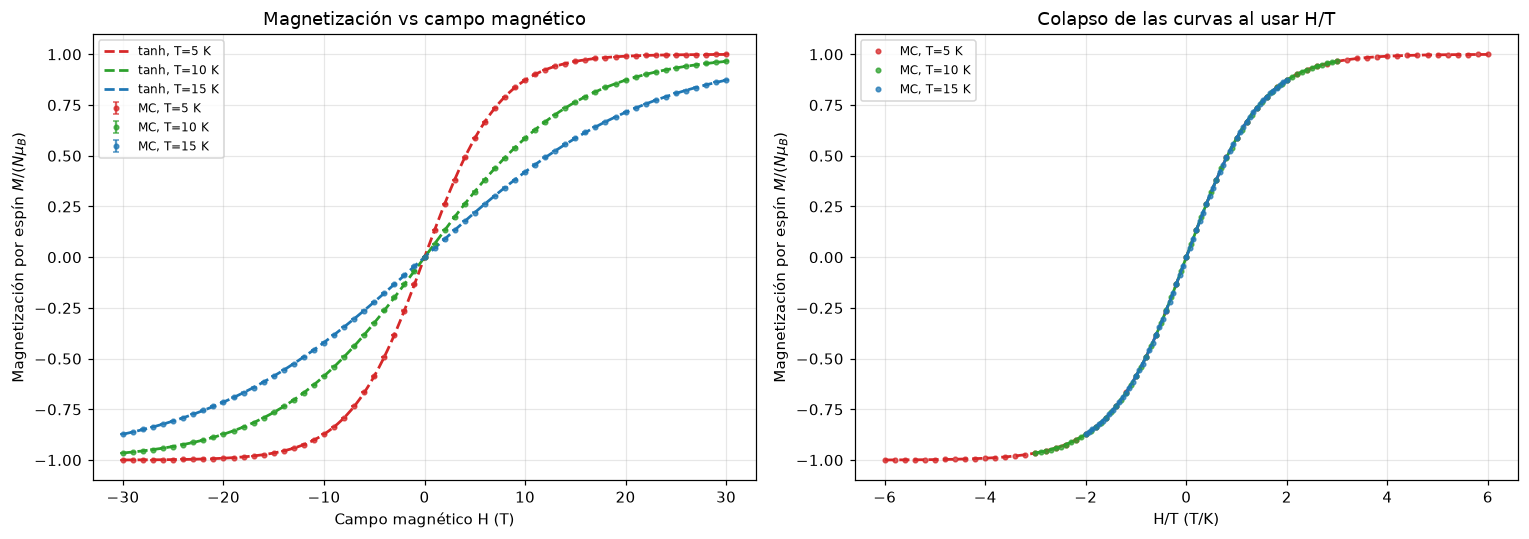

In [10]:
# Comparación con la magnetización analítica del paramagneto
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores = {5.0: 'tab:red', 10.0: 'tab:green', 15.0: 'tab:blue'}
H_fino = np.linspace(-30, 30, 400)

for T in temperaturas:
    datos_T = df_ising[df_ising['T (K)'] == T]
    color = colores[T]

    # Panel izquierdo: magnetización en función del campo
    axes[0].errorbar(
        datos_T['H (T)'], datos_T['M/(N mu_B)'],
        yerr=datos_T['Error estadístico'],
        fmt='o', markersize=3, capsize=2, color=color, alpha=0.75,
        label=f'MC, T={T:g} K'
    )
    axes[0].plot(
        H_fino, np.tanh(MU_B_OVER_K_B * H_fino / T),
        '--', color=color, lw=1.8,
        label=f'tanh, T={T:g} K'
    )

    # Panel derecho: colapso al graficar contra H/T
    axes[1].plot(
        datos_T['H (T)'] / T, datos_T['M/(N mu_B)'],
        'o', markersize=3, color=color, alpha=0.75,
        label=f'MC, T={T:g} K'
    )
    axes[1].plot(
        H_fino / T, np.tanh(MU_B_OVER_K_B * H_fino / T),
        '--', color=color, lw=1.8
    )

axes[0].set_xlabel('Campo magnético H (T)')
axes[0].set_ylabel(r'Magnetización por espín $M/(N\mu_B)$')
axes[0].set_title('Magnetización vs campo magnético')
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].set_xlabel('H/T (T/K)')
axes[1].set_ylabel(r'Magnetización por espín $M/(N\mu_B)$')
axes[1].set_title('Colapso de las curvas al usar H/T')
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


In [11]:
# Cuantificar la diferencia entre la simulación y el resultado analítico
print('Comparación MC vs tanh(mu_B H / k_B T)')
print('-' * 65)

for T in temperaturas:
    datos_T = df_ising[df_ising['T (K)'] == T]
    M_teorica = np.tanh(MU_B_OVER_K_B * datos_T['H (T)'] / T)
    diferencia = datos_T['M/(N mu_B)'] - M_teorica

    rmse = np.sqrt(np.mean(diferencia**2))
    error_maximo = np.max(np.abs(diferencia))
    error_medio = np.mean(np.abs(diferencia))

    print(f'T = {T:4.1f} K')
    print(f'  RMSE:               {rmse:.6f}')
    print(f'  Error máximo:       {error_maximo:.6f}')
    print(f'  Error medio absoluto: {error_medio:.6f}')
    print(f'  Tasa de aceptación media: {datos_T["Tasa de aceptación"].mean():.3f}')
    print()


Comparación MC vs tanh(mu_B H / k_B T)
-----------------------------------------------------------------
T =  5.0 K
  RMSE:               0.000447
  Error máximo:       0.001460
  Error medio absoluto: 0.000285
  Tasa de aceptación media: 0.085

T = 10.0 K
  RMSE:               0.000474
  Error máximo:       0.001282
  Error medio absoluto: 0.000386
  Tasa de aceptación media: 0.165

T = 15.0 K
  RMSE:               0.000466
  Error máximo:       0.001030
  Error medio absoluto: 0.000387
  Tasa de aceptación media: 0.231



Temperatura crítica de Onsager: Tc = 2.269185 J/k_B


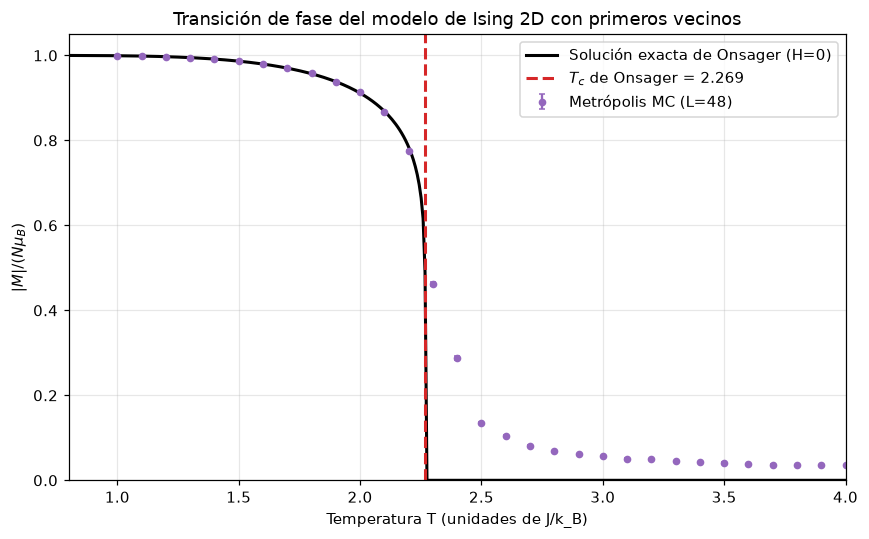

,T,|M|,Error estadístico,Tasa de aceptación
0,1.0,0.999235,0.000028,0.000372
1,1.1,0.998525,0.000039,0.000750
2,1.2,0.997003,0.000054,0.001493
3,1.3,0.994918,0.000076,0.002567
4,1.4,0.991352,0.000101,0.004289
5,1.5,0.986352,0.000135,0.006774
6,1.6,0.979500,0.000176,0.010058
7,1.7,0.970801,0.000220,0.014375
8,1.8,0.957683,0.000274,0.020397
9,1.9,0.938371,0.000406,0.028663


In [11]:
# Temperaturas en unidades reducidas (J = 1, k_B = 1)
temperaturas_reducidas = np.arange(1.0, 4.01, 0.1)
rng_interaccion = np.random.default_rng(2028)
registros_interaccion = []

for T in temperaturas_reducidas:
    semilla = int(rng_interaccion.integers(0, 2**32 - 1))
    red, mags, energias, tasa = metropolis_ising(
        L=48, T=T, H=0.0, J=1.0, mu=1.0,
        n_equil=1000, n_med=1000, seed=semilla,
        inicial=np.ones((48, 48), dtype=int)
    )
    # A H=0 la magnetización puede ser positiva o negativa.
    # Usamos |M| para promediar las dos ramas simétricas.
    magnetizacion_abs = np.abs(mags)
    registros_interaccion.append({
        'T': T,
        '|M|': magnetizacion_abs.mean(),
        'Error estadístico': magnetizacion_abs.std(ddof=1) / np.sqrt(len(magnetizacion_abs)),
        'Tasa de aceptación': tasa,
    })

df_interaccion = pd.DataFrame(registros_interaccion)

# Temperatura crítica de Onsager para J = 1, k_B = 1
Tc_onsager = 2.0 / np.log(1.0 + np.sqrt(2.0))
print(f'Temperatura crítica de Onsager: Tc = {Tc_onsager:.6f} J/k_B')

# Magnetización exacta de Onsager a H = 0 (solo válida para T < Tc)
T_fino = np.linspace(0.8, 4.0, 400)
M_onsager = np.zeros_like(T_fino)
mascara_onsager = T_fino < Tc_onsager
M_onsager[mascara_onsager] = (
    1.0 - np.sinh(2.0 / T_fino[mascara_onsager])**(-4)
)**(1.0 / 8.0)

plt.figure(figsize=(8, 5))
plt.errorbar(
    df_interaccion['T'], df_interaccion['|M|'],
    yerr=df_interaccion['Error estadístico'],
    fmt='o', markersize=4, capsize=2, color='tab:purple',
    label='Metrópolis MC (L=48)'
)
plt.plot(T_fino, M_onsager, 'k-', lw=2, label='Solución exacta de Onsager (H=0)')
plt.axvline(Tc_onsager, color='tab:red', linestyle='--', lw=2,
            label=f'$T_c$ de Onsager = {Tc_onsager:.3f}')
plt.xlabel('Temperatura T (unidades de J/k_B)')
plt.ylabel(r'$|M|/(N\mu_B)$')
plt.title('Transición de fase del modelo de Ising 2D con primeros vecinos')
plt.xlim(0.8, 4.0)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

df_interaccion.head(10)
